# Part 1: Required baseline
Persistence and the fixed ridge model (29 features, `Ridge(alpha=1.0)`, raw features, pooled over all stations), evaluated on the validation period (targets 1 Sep – 30 Nov 2024).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

DATA = "data"

## 1. Load data

In [2]:
W = pd.read_csv(f"{DATA}/bihar_pm25_hourly_jan_nov_2024.csv",
                index_col="timestamp", parse_dates=True)
stations = pd.read_csv(f"{DATA}/bihar_stations.csv",
                       dtype={"sensor_id": str}).set_index("sensor_id")

assert list(stations.index) == list(W.columns)
assert W.shape == (8040, 468) and not W.isna().any().any()
assert W.index.equals(pd.date_range("2024-01-01 00:00", "2024-11-30 23:00", freq="h"))
print(W.shape, W.index.min(), "to", W.index.max())

(8040, 468) 2024-01-01 00:00:00 to 2024-11-30 23:00:00


## 2. Issue times and targets
The issue time is day d at 12:00 and the target is day d+1 at 12:00. A row belongs to training or validation by its target date. Ridge needs 24 hours of history, so 1 Jan is dropped and the first issue time is 2 Jan 12:00.

Every array from here on is ordered time first, then station, in column order.

In [3]:
def noon_issue_times(first_target, last_target):
    targets = pd.date_range(first_target, last_target, freq="D")
    return targets - pd.Timedelta(hours=24)

T_train = noon_issue_times("2024-01-03 12:00", "2024-08-31 12:00")
T_val   = noon_issue_times("2024-09-01 12:00", "2024-11-30 12:00")

def targets(T):
    """Target readings, flattened: issue time first, then station."""
    return W.loc[T + pd.Timedelta(hours=24)].to_numpy().ravel()

y_train, y_val = targets(T_train), targets(T_val)

print(f"Training:   {len(T_train)} issue days x 468 stations = {len(y_train):,} rows "
      f"(issue {T_train[0]} to {T_train[-1]})")
print(f"Validation: {len(T_val)} issue days x 468 stations = {len(y_val):,} rows "
      f"(issue {T_val[0]} to {T_val[-1]})")

Training:   242 issue days x 468 stations = 113,256 rows (issue 2024-01-02 12:00:00 to 2024-08-30 12:00:00)
Validation: 91 issue days x 468 stations = 42,588 rows (issue 2024-08-31 12:00:00 to 2024-11-29 12:00:00)


## 3. Evaluation and persistence
Errors in µg/m³, forecasts clipped at 0, overall and per validation month (by target date).

In [4]:
val_months = np.repeat((T_val + pd.Timedelta(hours=24)).month, 468)

def evaluate(pred, y=None, months=None):
    y = y_val if y is None else y
    months = val_months if months is None else months
    pred = np.clip(pred, 0, None)
    err = pred - y
    out = {"RMSE": np.sqrt(np.mean(err**2)), "MAE": np.mean(np.abs(err))}
    for m, name in [(9, "Sep"), (10, "Oct"), (11, "Nov")]:
        e = err[months == m]
        out[f"RMSE {name}"] = np.sqrt(np.mean(e**2))
        out[f"MAE {name}"] = np.mean(np.abs(e))
    return out

pred_persist = W.loc[T_val].to_numpy().ravel()    # reading at issue time
pd.Series(evaluate(pred_persist)).round(2)

RMSE        32.75
MAE         17.47
RMSE Sep    23.33
MAE Sep      8.91
RMSE Oct    20.22
MAE Oct     11.97
RMSE Nov    47.81
MAE Nov     31.70
dtype: float64

## 4. Ten nearest neighbours
Coordinates converted to km with the spec's formula; Euclidean distance; a station is never its own neighbour.

In [5]:
x = (stations.longitude - 85.5) * 100.3
y = (stations.latitude - 25.7) * 110.6
xy = np.column_stack([x, y])

D = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(axis=2))   # 468 x 468 km
np.fill_diagonal(D, np.inf)                                         # never your own neighbour
nbr_idx = np.argsort(D, axis=1, kind="stable")[:, :10]

A = np.zeros((468, 468))                     # averaging matrix: 0.1 on each of the 10 neighbours
A[np.arange(468)[:, None], nbr_idx] = 0.1
assert np.allclose(A.sum(axis=1), 1) and np.all(np.diag(A) == 0)

srt = np.sort(D, axis=1)
print("Ties at the 10th neighbour:", int(np.isclose(srt[:, 9], srt[:, 10]).sum()))
print("Neighbours of station", stations.index[0], ":", list(stations.index[nbr_idx[0]]))

Ties at the 10th neighbour: 0
Neighbours of station 4 : ['14', '9', '19', '6', '20', '39', '37', '38', '23', '29']


## 5. The 29 features
24 hourly lags (t … t−23 h); mean of the 10 neighbours at t; mean of the 10 neighbours over t−23 h … t; network mean at t; sin and cos of 2πd/365.

In [6]:
def part1_features(W, issue_times):
    """29 features per (issue time, station), using readings at or before each issue time."""
    T = pd.DatetimeIndex(issue_times)
    # L[i, s, k] = reading of station s at T[i] - k hours
    L = np.stack([W.reindex(T - pd.Timedelta(hours=k)).to_numpy() for k in range(24)], axis=2)
    n = len(T)

    lags       = L.reshape(n * 468, 24)                                    # 24 features
    nbr_now    = (L[:, :, 0] @ A.T).ravel()                                # neighbours at t
    nbr_mean24 = np.einsum("tsk,js->tjk", L, A).mean(axis=2).ravel()       # neighbours over 24 h
    net_now    = np.repeat(L[:, :, 0].mean(axis=1), 468)                   # all 468 at t
    d          = np.repeat((T.normalize() - pd.Timestamp("2024-01-01")).days.to_numpy(), 468)

    return np.column_stack([lags, nbr_now, nbr_mean24, net_now,
                            np.sin(2 * np.pi * d / 365), np.cos(2 * np.pi * d / 365)])

X_train = part1_features(W, T_train)
X_val   = part1_features(W, T_val)
print(X_train.shape, X_val.shape)
assert not np.isnan(X_train).any() and not np.isnan(X_val).any()

(113256, 29) (42588, 29)


## 6. Checks
(a) lag 0 equals the persistence forecast (row alignment); (b) one row recomputed by hand; (c) no leakage: features computed from history truncated at t are identical.

In [7]:
# (a) alignment
assert np.allclose(X_val[:, 0], pred_persist)

# (b) one row by hand: station '100' at 2024-03-15 12:00
t, s = pd.Timestamp("2024-03-15 12:00"), "100"
i, j = T_train.get_loc(t), list(W.columns).index(s)
row = X_train[i * 468 + j]
nb = stations.index[nbr_idx[j]]
d = (t.normalize() - pd.Timestamp("2024-01-01")).days
expected = [W.loc[t, s], W.loc[t - pd.Timedelta(hours=23), s],
            W.loc[t, nb].mean(),
            W.loc[t - pd.Timedelta(hours=23):t, nb].to_numpy().mean(),
            W.loc[t].mean(),
            np.sin(2 * np.pi * d / 365), np.cos(2 * np.pi * d / 365)]
assert np.allclose(row[[0, 23, 24, 25, 26, 27, 28]], expected)
assert y_train[i * 468 + j] == W.loc[t + pd.Timedelta(hours=24), s]

# (c) leakage
assert np.allclose(part1_features(W, [t]), part1_features(W.loc[:t], [t]))
print("All checks passed")

All checks passed


## 7. Ridge

In [8]:
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
pred_ridge = np.clip(ridge.predict(X_val), 0, None)
pd.Series(evaluate(pred_ridge)).round(2)

RMSE        29.58
MAE         18.16
RMSE Sep    20.34
MAE Sep     10.35
RMSE Oct    19.36
MAE Oct     13.46
RMSE Nov    43.06
MAE Nov     30.81
dtype: float64

## 8. Results

In [11]:
results = pd.DataFrame({"Persistence": evaluate(pred_persist),
                        "Ridge (Part 1)": evaluate(pred_ridge)}).T.round(2)
display(results)

,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


In [12]:
for name, p in [("Persistence", pred_persist), ("Ridge", pred_ridge)]:
    e = p - y_val
    print(f"{name:12s} mean error {e.mean():+.2f}  median error {np.median(e):+.2f}  "
          f"share |error| > 60: {np.mean(np.abs(e) > 60) * 100:.1f}%")
print(f"Validation targets: median {np.median(y_val):.1f}, mean {y_val.mean():.1f} µg/m³")

Persistence  mean error -0.47  median error -0.75  share |error| > 60: 5.6%
Ridge        mean error +5.32  median error +7.20  share |error| > 60: 4.7%
Validation targets: median 32.3, mean 52.8 µg/m³


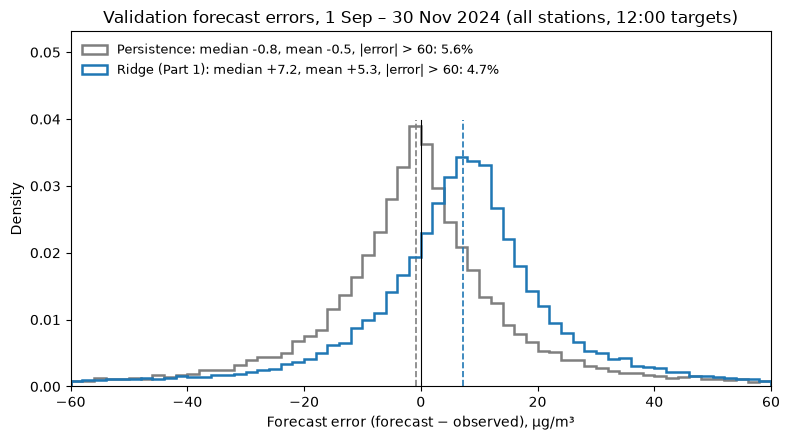

In [13]:
err_ridge   = pred_ridge - y_val
err_persist = pred_persist - y_val

bins = np.arange(-60, 61, 2)                      # 2 µg/m³ bins over ±60
fig, ax = plt.subplots(figsize=(8, 4.5))
for err, name, color in [(err_persist, "Persistence", "tab:gray"),
                         (err_ridge,   "Ridge (Part 1)", "tab:blue")]:
    tail = np.mean(np.abs(err) > 60) * 100        # share of errors off the plot
    w = np.full(err.shape, 1 / (len(err) * 2))    # density over ALL errors, so tails still count
    ax.hist(err, bins=bins, weights=w, histtype="step", linewidth=1.8, color=color,
            label=f"{name}: median {np.median(err):+.1f}, mean {err.mean():+.1f}, "
                  f"|error| > 60: {tail:.1f}%")
    ax.axvline(np.median(err), color=color, linestyle="--", linewidth=1.2, ymax=0.75)

ax.axvline(0, color="black", linewidth=0.8, ymax=0.75)
ax.set_xlim(-60, 60)
ax.set_ylim(0, ax.get_ylim()[1] * 1.3)            # headroom for the legend
ax.set_xlabel("Forecast error (forecast − observed), µg/m³")
ax.set_ylabel("Density")
ax.set_title("Validation forecast errors, 1 Sep – 30 Nov 2024 (all stations, 12:00 targets)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("error_histogram.png", dpi=150)
plt.show()

### RMSE vs MAE
Neither baseline wins on both metrics. Ridge has the lower RMSE (29.58 vs 32.75 µg/m³) but persistence has the lower MAE (17.47 vs 18.16); the MAE gap is largest in clean September (8.91 vs 10.35).

A model trained on squared error predicts the conditional mean, while absolute error is minimised by the conditional median. PM2.5 is right-skewed (validation targets: median 32.3, mean 52.8 µg/m³), so the mean sits above the median. Ridge accordingly over-predicts on a typical day (median error +7.2 µg/m³), which costs MAE because every day counts equally. In exchange it makes fewer large misses (4.7% of errors beyond ±60 µg/m³ vs 5.6% for persistence), and RMSE punishes large misses most. Persistence is almost unbiased (median error −0.8) and nearly exact on stable days, but it misses badly when pollution changes sharply.

### Decisions
- d = days since 1 Jan 2024 for the issue day; divisor 365 even though 2024 is a leap year.
- The network mean includes the station itself (all 468 stations).
- The 24 h neighbour mean averages all 240 readings (10 stations × 24 hours).
- Neighbours by Euclidean distance in km using the spec's conversion; there are no ties at the 10th neighbour.
- Training uses 113,256 rows: every station on every issue day from 2 Jan to 30 Aug (targets 3 Jan to 31 Aug).